# PolymerCode AI — ANN Project

This notebook trains and evaluates two image-classification models:
- **Custom CNN**
- **VGG-16 (transfer learning)**

Run the cells from top to bottom. Upload the dataset ZIP when asked. The model architectures, training settings, and final evaluation logic are preserved from the original notebook.

# 1. Upload the Dataset

In [1]:
# 1. Upload or Locate the Dataset
try:
    from google.colab import files
    uploaded = files.upload()
    zip_files = [
        name for name in uploaded
        if name.lower().endswith(".zip")
    ]
except Exception:
    import glob
    zip_files = glob.glob("*.zip")
    uploaded = {f: open(f, "rb").read() for f in zip_files}

print("Available ZIP files:", zip_files)


Available ZIP files: ['polymercode-classification-dataset (3).zip']


# 2. Extract the Dataset

In [2]:
from pathlib import Path
import zipfile

zip_name = next(
    (name for name in uploaded if name.endswith(".zip")),
    None
)
if zip_name is None:
    candidates = list(Path(".").glob("*.zip"))
    if candidates:
        zip_name = str(candidates[0])

assert zip_name is not None, "Please upload or provide the dataset ZIP first."

data_dir = Path("PolymerCode-AI/data/classification_dataset")
data_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as z:
    z.extractall(data_dir)

print("Dataset extracted to:", data_dir.resolve())
print("\nTop-level contents:")

for item in sorted(data_dir.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)


Dataset extracted to: D:\p1\PolymerCode-AI\data\classification_dataset

Top-level contents:
📁 classification_dataset


# 3. Check Dataset and Image Counts

In [3]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Find the extracted classification dataset
matches = [
    p for p in Path(".").rglob("metadata.csv")
    if all((p.parent / split).is_dir()
           for split in ["train", "val", "test"])
]

if not matches:
    raise FileNotFoundError(
        "Dataset not found. Upload and extract the ZIP first."
    )

DATA_DIR = matches[0].parent
print("Dataset location:", DATA_DIR.resolve())

# Count images in each split and class
extensions = {".jpg", ".jpeg", ".png", ".webp"}
rows = []

for split in ["train", "val", "test"]:
    for folder in sorted((DATA_DIR / split).iterdir()):
        if folder.is_dir():
            count = sum(
                1 for f in folder.iterdir()
                if f.is_file() and f.suffix.lower() in extensions
            )
            rows.append({
                "Split": split,
                "Class": folder.name,
                "Images": count
            })

counts = pd.DataFrame(rows)
print("\nImage counts:")
display(counts.pivot(
    index="Class", columns="Split",
    values="Images"
).fillna(0).astype(int))

print("\nTotal images:", int(counts["Images"].sum()))

metadata = pd.read_csv(DATA_DIR / "metadata.csv")
print("Metadata records:", len(metadata))
print("\nDataset audit:")
display(metadata[[
    "source_image", "new_split",
    "class_name", "resin_code"
]].head())


Dataset location: D:\p1\PolymerCode-AI\data\classification_dataset\classification_dataset

Image counts:


Split,test,train,val
Class,,,
HDPE,9,51,9
LDPE,15,58,15
OTHER,11,42,9
PET,15,74,15
PP,24,114,24
PS,4,21,6
PVC,3,14,3



Total images: 536
Metadata records: 536

Dataset audit:


,source_image,new_split,class_name,resin_code
0,train/images/00bfb003-97c9-4329-bd55-c54a12811...,train,OTHER,7
1,train/images/30b14a3f-487a-4f19-80b1-f24ddb072...,train,PS,6
2,train/images/85943598-ec9b-4da5-9221-8c32b5742...,val,PET,1
3,train/images/BBOZ2526_jpg.rf.aa065d4735f4db7b2...,train,PET,1
4,train/images/BMOY1981_jpg.rf.063246b2fd1e24b79...,train,OTHER,7


# 4. View Sample Images

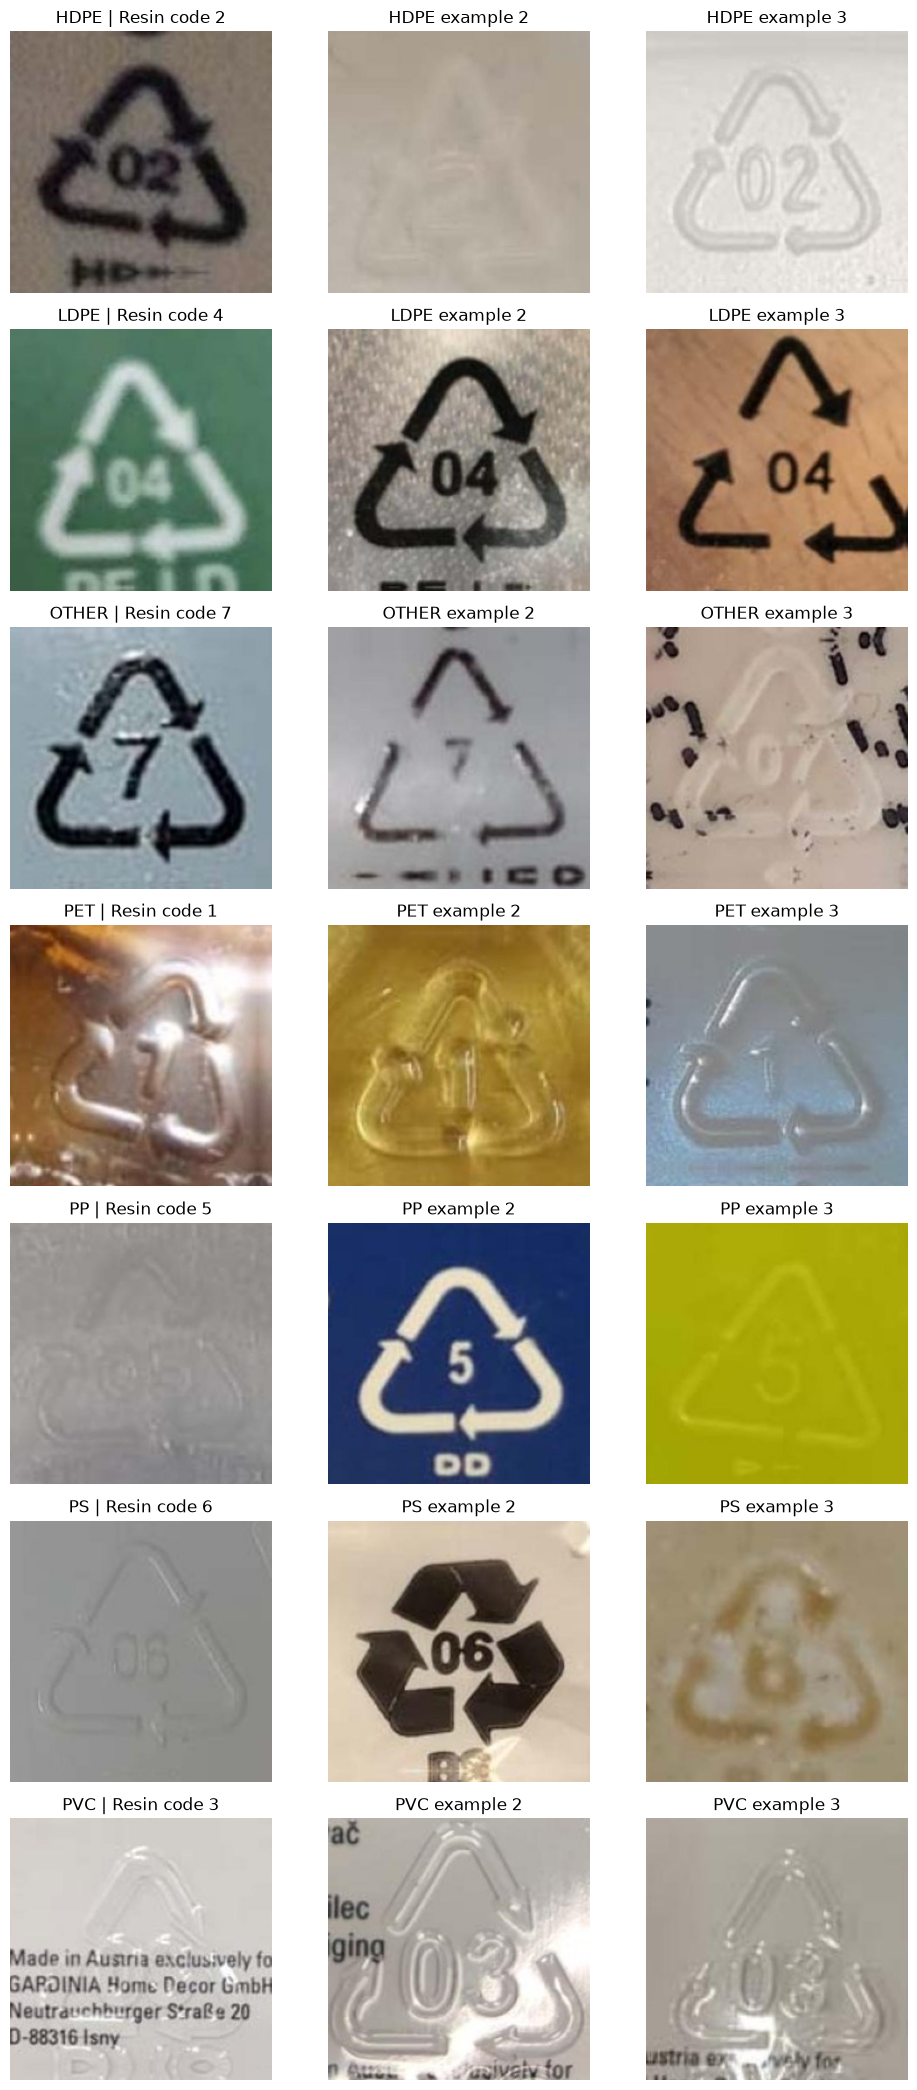

In [4]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = Path(DATA_DIR)

resin_codes = {
    "PET": 1,
    "HDPE": 2,
    "PVC": 3,
    "LDPE": 4,
    "PP": 5,
    "PS": 6,
    "OTHER": 7,
}

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

classes = sorted(
    folder.name
    for folder in (DATA_DIR / "train").iterdir()
    if folder.is_dir()
)

fig, axes = plt.subplots(
    len(classes), 3,
    figsize=(10, 3 * len(classes))
)

for row, class_name in enumerate(classes):
    files = sorted(
        path for path in (DATA_DIR / "train" / class_name).iterdir()
        if path.suffix.lower() in image_extensions
    )

    for col, ax in enumerate(axes[row]):
        ax.axis("off")

        if col < len(files):
            with Image.open(files[col]) as image:
                ax.imshow(image.convert("RGB"))

            ax.set_title(
                f"{class_name} | Resin code {resin_codes[class_name]}"
                if col == 0 else f"{class_name} example {col + 1}"
            )

plt.tight_layout()
plt.show()

# 5. Prepare Data for Training

In [5]:
import random
import numpy as np
import torch
import pandas as pd

from pathlib import Path
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATA_DIR = Path(DATA_DIR)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ImageNet normalization: also useful for our later VGG-16 experiment
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.10, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.ImageFolder(DATA_DIR / "train", transform=train_transform)
val_ds = datasets.ImageFolder(DATA_DIR / "val", transform=eval_transform)
test_ds = datasets.ImageFolder(DATA_DIR / "test", transform=eval_transform)

assert train_ds.class_to_idx == val_ds.class_to_idx == test_ds.class_to_idx

classes = train_ds.classes
num_classes = len(classes)

train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=32, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

# Moderate class weighting: reduces bias toward larger classes
counts = np.bincount(train_ds.targets, minlength=num_classes)
weights = np.sqrt(counts.sum() / (num_classes * counts))
weights = weights / weights.mean()
class_weights = torch.tensor(weights, dtype=torch.float32, device=device)

print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Class mapping:", train_ds.class_to_idx)
print("Training counts:", dict(zip(classes, counts.tolist())))
print("Class weights:", dict(zip(classes, weights.round(3).tolist())))
print("Batches — train:", len(train_loader), "| validation:", len(val_loader))


Device: cpu
GPU: CPU
Class mapping: {'HDPE': 0, 'LDPE': 1, 'OTHER': 2, 'PET': 3, 'PP': 4, 'PS': 5, 'PVC': 6}
Training counts: {'HDPE': 51, 'LDPE': 58, 'OTHER': 42, 'PET': 74, 'PP': 114, 'PS': 21, 'PVC': 14}
Class weights: {'HDPE': 0.874, 'LDPE': 0.82, 'OTHER': 0.964, 'PET': 0.726, 'PP': 0.585, 'PS': 1.363, 'PVC': 1.669}
Batches — train: 12 | validation: 3


# 6. Build the Custom CNN

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.block(x)


class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),       # 224 -> 112
            ConvBlock(32, 64),      # 112 -> 56
            ConvBlock(64, 128),     # 56 -> 28
            ConvBlock(128, 256),    # 28 -> 14
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


model = CustomCNN(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3, weight_decay=1e-4
)

print(model)
print(f"\nTrainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CustomCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=Fal

# 7. Train the Custom CNN

In [7]:
from copy import deepcopy
from pathlib import Path
import time
import pickle
import shutil
import matplotlib.pyplot as plt

PROJECT_DIR = Path("PolymerCode-AI")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Also ensure root models directory exists
ROOT_MODEL_DIR = Path("models")
ROOT_MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "custom_cnn_best.pt"

MAX_EPOCHS = 30
PATIENCE = 7

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=2
)

def run_epoch(loader, training):
    model.train(training)
    total_loss = 0.0
    all_true, all_pred = [], []

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = logits.argmax(dim=1)

            all_true.extend(labels.detach().cpu().tolist())
            all_pred.extend(predictions.detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(all_true, all_pred),
        "macro_f1": f1_score(
            all_true, all_pred,
            labels=list(range(num_classes)),
            average="macro",
            zero_division=0
        )
    }


history = []
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    train_metrics = run_epoch(train_loader, training=True)
    val_metrics = run_epoch(val_loader, training=False)

    scheduler.step(val_metrics["loss"])

    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_macro_f1": val_metrics["macro_f1"],
        "learning_rate": optimizer.param_groups[0]["lr"]
    }
    history.append(row)

    improved = val_metrics["loss"] < best_val_loss - 1e-4

    if improved:
        best_val_loss = val_metrics["loss"]
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "class_to_idx": train_ds.class_to_idx,
            "classes": classes,
            "epoch": epoch,
            "validation_loss": best_val_loss
        }, BEST_MODEL_PATH)
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"val loss {val_metrics['loss']:.4f} | "
        f"val accuracy {val_metrics['accuracy']:.3f} | "
        f"val macro-F1 {val_metrics['macro_f1']:.3f}",
        flush=True
    )

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.", flush=True)
        break

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_DIR / "custom_cnn_training_history.csv", index=False)

# Restore the best validation-loss checkpoint
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("\nTraining finished.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.1f} minutes")
print("Model checkpoint saved to:", BEST_MODEL_PATH)
print("History saved to:", RESULTS_DIR / "custom_cnn_training_history.csv")

# ==================== SAVE MODEL AS PKL FORMAT WITH WEIGHTS AND BIASES ====================
print("\n--- Saving Custom CNN in PKL format along with weights and biases ---")

# Extract individual weights and biases
weights_dict = {}
biases_dict = {}
named_params_dict = {}

for name, param in model.named_parameters():
    param_cpu = param.detach().cpu()
    named_params_dict[name] = {
        "tensor": param_cpu,
        "numpy": param_cpu.numpy(),
        "shape": list(param_cpu.shape),
        "requires_grad": param.requires_grad
    }
    if "weight" in name:
        weights_dict[name] = param_cpu
    elif "bias" in name:
        biases_dict[name] = param_cpu

# State dict with all parameters & buffers (BatchNorm running_mean/var etc.)
state_dict_cpu = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

custom_cnn_weights_and_biases = {
    "weights": weights_dict,
    "biases": biases_dict,
    "named_parameters": named_params_dict,
    "state_dict": state_dict_cpu,
    "classes": classes,
    "class_to_idx": train_ds.class_to_idx
}

# 1. Save weights and biases pkl
with open(MODEL_DIR / "custom_cnn_weights_and_biases.pkl", "wb") as f:
    pickle.dump(custom_cnn_weights_and_biases, f)

# 2. Save complete model object pkl
with open(MODEL_DIR / "custom_cnn_model.pkl", "wb") as f:
    pickle.dump(model, f)

# 3. Save complete bundle (model + weights + biases + class mappings + metadata)
custom_cnn_pkl_bundle = {
    "model": model,
    "model_state_dict": state_dict_cpu,
    "weights_and_biases": custom_cnn_weights_and_biases,
    "weights": weights_dict,
    "biases": biases_dict,
    "class_to_idx": train_ds.class_to_idx,
    "classes": classes,
    "best_epoch": best_epoch,
    "validation_loss": best_val_loss
}

with open(MODEL_DIR / "custom_cnn.pkl", "wb") as f:
    pickle.dump(custom_cnn_pkl_bundle, f)

# Copy to root models directory for convenience
for fname in ["custom_cnn.pkl", "custom_cnn_weights_and_biases.pkl", "custom_cnn_model.pkl", "custom_cnn_best.pt"]:
    shutil.copy2(MODEL_DIR / fname, ROOT_MODEL_DIR / fname)

print(f"Saved: {MODEL_DIR / 'custom_cnn.pkl'} (and models/custom_cnn.pkl)")
print(f"Saved: {MODEL_DIR / 'custom_cnn_weights_and_biases.pkl'}")
print(f"Saved: {MODEL_DIR / 'custom_cnn_model.pkl'}")


Epoch 01/30 | train loss 1.9213 | val loss 1.9123 | val accuracy 0.284 | val macro-F1 0.115


Epoch 02/30 | train loss 1.8523 | val loss 2.0360 | val accuracy 0.259 | val macro-F1 0.156


Epoch 03/30 | train loss 1.8391 | val loss 2.0586 | val accuracy 0.173 | val macro-F1 0.094


Epoch 04/30 | train loss 1.8047 | val loss 1.9326 | val accuracy 0.247 | val macro-F1 0.175


Epoch 05/30 | train loss 1.7717 | val loss 1.8952 | val accuracy 0.235 | val macro-F1 0.168


...

Epoch 16/30 | train loss 1.5871 | val loss 1.8067 | val accuracy 0.370 | val macro-F1 0.286


Epoch 17/30 | train loss 1.5733 | val loss 1.8260 | val accuracy 0.333 | val macro-F1 0.261


Epoch 18/30 | train loss 1.5577 | val loss 1.7964 | val accuracy 0.296 | val macro-F1 0.236


Early stopping at epoch 18.



Training finished.
Best epoch: 11
Best validation loss: 1.7512
Elapsed time: 10.7 minutes
Model checkpoint saved to: PolymerCode-AI\models\custom_cnn_best.pt
History saved to: PolymerCode-AI\results\custom_cnn_training_history.csv

--- Saving Custom CNN in PKL format along with weights and biases ---
Saved: PolymerCode-AI\models\custom_cnn.pkl (and models/custom_cnn.pkl)
Saved: PolymerCode-AI\models\custom_cnn_weights_and_biases.pkl
Saved: PolymerCode-AI\models\custom_cnn_model.pkl


# 8. Plot Custom CNN Loss

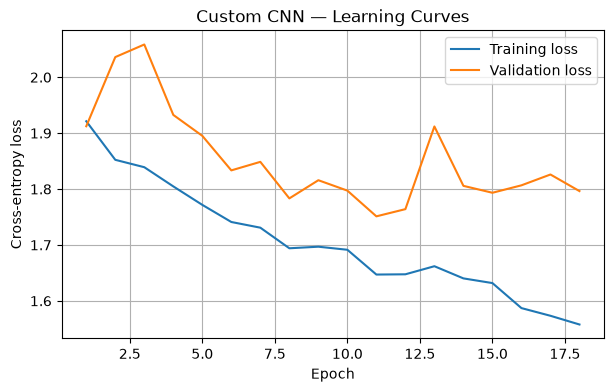

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Training loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Custom CNN — Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

# 9. Plot Custom CNN Macro-F1

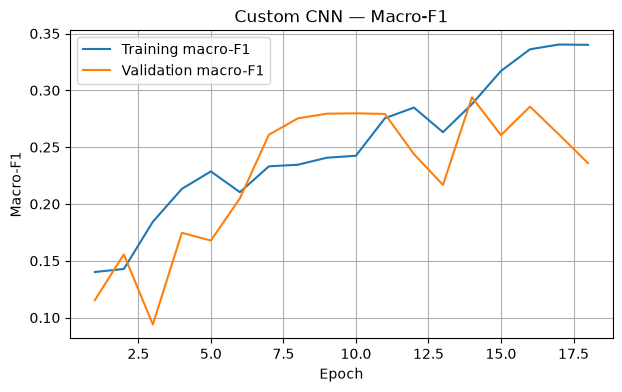

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history_df["epoch"], history_df["train_macro_f1"], label="Training macro-F1")
plt.plot(history_df["epoch"], history_df["val_macro_f1"], label="Validation macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Custom CNN — Macro-F1")
plt.legend()
plt.grid(True)
plt.show()

# 10. Build and Train VGG-16

In [10]:
import time
from copy import deepcopy
from pathlib import Path
import pickle
import shutil

import torch
import pandas as pd
from torch import nn
from torchvision.models import vgg16, VGG16_Weights
from sklearn.metrics import accuracy_score, f1_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device for VGG-16:", device)

PROJECT_DIR = Path("PolymerCode-AI")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
ROOT_MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ROOT_MODEL_DIR.mkdir(parents=True, exist_ok=True)

VGG_PATH = MODEL_DIR / "vgg16_best.pt"

# Load pretrained weights. The first run may download them.
try:
    vgg = vgg16(weights=VGG16_Weights.DEFAULT)
except Exception as e:
    raise RuntimeError(
        "Could not load pretrained VGG-16 weights. "
        "Check internet access and rerun this cell."
    ) from e

# Global average pooling reduces classifier size for our small dataset.
vgg.avgpool = nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.4),
    nn.Linear(256, num_classes)
)

# Phase 1: freeze the pretrained convolutional feature extractor.
for param in vgg.features.parameters():
    param.requires_grad = False

vgg = vgg.to(device)
criterion_vgg = nn.CrossEntropyLoss(weight=class_weights)

def vgg_epoch(loader, training, optimizer=None):
    vgg.train(training)
    total_loss = 0.0
    targets, predictions = [], []

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = vgg(images)
            loss = criterion_vgg(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            targets.extend(labels.detach().cpu().tolist())
            predictions.extend(logits.argmax(1).detach().cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(targets, predictions),
        "macro_f1": f1_score(
            targets, predictions,
            labels=list(range(num_classes)),
            average="macro",
            zero_division=0
        )
    }

def snapshot():
    return {
        k: v.detach().cpu().clone()
        for k, v in vgg.state_dict().items()
    }

history_vgg = []
best_val_loss = float("inf")
best_state = None
start_time = time.time()

# Phase 1: train the new classifier head.
optimizer = torch.optim.AdamW(
    vgg.classifier.parameters(), lr=5e-4, weight_decay=1e-4
)

for epoch in range(1, 6):
    train_m = vgg_epoch(train_loader, True, optimizer)
    val_m = vgg_epoch(val_loader, False)

    history_vgg.append({
        "phase": "head",
        "epoch": epoch,
        "train_loss": train_m["loss"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"]
    })

    print(
        f"Head {epoch}/5 | train loss {train_m['loss']:.4f} | "
        f"val loss {val_m['loss']:.4f} | "
        f"val accuracy {val_m['accuracy']:.3f} | "
        f"val macro-F1 {val_m['macro_f1']:.3f}",
        flush=True
    )

    if val_m["loss"] < best_val_loss:
        best_val_loss = val_m["loss"]
        best_state = snapshot()

# Restore best head-only model before fine-tuning.
vgg.load_state_dict(best_state)

# Phase 2: fine-tune only the final VGG-16 convolutional block.
for param in vgg.features[24:].parameters():
    param.requires_grad = True

optimizer = torch.optim.AdamW([
    {"params": vgg.features[24:].parameters(), "lr": 1e-5},
    {"params": vgg.classifier.parameters(), "lr": 1e-4}
], weight_decay=1e-4)

patience = 4
no_improvement = 0

for epoch in range(1, 11):
    train_m = vgg_epoch(train_loader, True, optimizer)
    val_m = vgg_epoch(val_loader, False)

    history_vgg.append({
        "phase": "fine_tune",
        "epoch": epoch,
        "train_loss": train_m["loss"],
        "val_loss": val_m["loss"],
        "val_accuracy": val_m["accuracy"],
        "val_macro_f1": val_m["macro_f1"]
    })

    print(
        f"Fine-tune {epoch}/10 | train loss {train_m['loss']:.4f} | "
        f"val loss {val_m['loss']:.4f} | "
        f"val accuracy {val_m['accuracy']:.3f} | "
        f"val macro-F1 {val_m['macro_f1']:.3f}",
        flush=True
    )

    if val_m["loss"] < best_val_loss - 1e-4:
        best_val_loss = val_m["loss"]
        best_state = snapshot()
        no_improvement = 0
    else:
        no_improvement += 1

    if no_improvement >= patience:
        print("Early stopping fine-tuning.", flush=True)
        break

# Save the best checkpoint selected on validation loss.
vgg.load_state_dict(best_state)
torch.save({
    "model_state_dict": best_state,
    "class_to_idx": train_ds.class_to_idx,
    "classes": classes,
    "best_validation_loss": best_val_loss
}, VGG_PATH)

history_vgg_df = pd.DataFrame(history_vgg)
history_vgg_df.to_csv(
    RESULTS_DIR / "vgg16_training_history.csv", index=False
)

print("\nVGG-16 training complete.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Elapsed time: {(time.time() - start_time) / 60:.1f} minutes")
print("Checkpoint:", VGG_PATH)

# ==================== SAVE VGG-16 AS PKL FORMAT WITH WEIGHTS AND BIASES ====================
print("\n--- Saving VGG-16 in PKL format along with weights and biases ---")

vgg_weights = {}
vgg_biases = {}
vgg_named_params = {}

for name, param in vgg.named_parameters():
    param_cpu = param.detach().cpu()
    vgg_named_params[name] = {
        "tensor": param_cpu,
        "numpy": param_cpu.numpy(),
        "shape": list(param_cpu.shape),
        "requires_grad": param.requires_grad
    }
    if "weight" in name:
        vgg_weights[name] = param_cpu
    elif "bias" in name:
        vgg_biases[name] = param_cpu

vgg_state_dict_cpu = {k: v.detach().cpu().clone() for k, v in vgg.state_dict().items()}

vgg_weights_and_biases = {
    "weights": vgg_weights,
    "biases": vgg_biases,
    "named_parameters": vgg_named_params,
    "state_dict": vgg_state_dict_cpu,
    "classes": classes,
    "class_to_idx": train_ds.class_to_idx
}

# 1. Save weights and biases pkl
with open(MODEL_DIR / "vgg16_weights_and_biases.pkl", "wb") as f:
    pickle.dump(vgg_weights_and_biases, f)

# 2. Save complete model object pkl
with open(MODEL_DIR / "vgg16_model.pkl", "wb") as f:
    pickle.dump(vgg, f)

# 3. Save complete bundle
vgg_pkl_bundle = {
    "model": vgg,
    "model_state_dict": vgg_state_dict_cpu,
    "weights_and_biases": vgg_weights_and_biases,
    "weights": vgg_weights,
    "biases": vgg_biases,
    "class_to_idx": train_ds.class_to_idx,
    "classes": classes,
    "best_validation_loss": best_val_loss
}

with open(MODEL_DIR / "vgg16.pkl", "wb") as f:
    pickle.dump(vgg_pkl_bundle, f)

# Copy to root models directory
for fname in ["vgg16.pkl", "vgg16_weights_and_biases.pkl", "vgg16_model.pkl", "vgg16_best.pt"]:
    shutil.copy2(MODEL_DIR / fname, ROOT_MODEL_DIR / fname)

print(f"Saved: {MODEL_DIR / 'vgg16.pkl'} (and models/vgg16.pkl)")
print(f"Saved: {MODEL_DIR / 'vgg16_weights_and_biases.pkl'}")
print(f"Saved: {MODEL_DIR / 'vgg16_model.pkl'}")


Using device for VGG-16: cpu


Head 1/5 | train loss 1.9015 | val loss 1.8155 | val accuracy 0.481 | val macro-F1 0.251


Head 2/5 | train loss 1.8187 | val loss 1.7454 | val accuracy 0.407 | val macro-F1 0.171


Head 3/5 | train loss 1.7230 | val loss 1.6682 | val accuracy 0.444 | val macro-F1 0.330


Head 4/5 | train loss 1.6430 | val loss 1.5970 | val accuracy 0.444 | val macro-F1 0.308


...

Fine-tune 8/10 | train loss 1.1838 | val loss 1.3509 | val accuracy 0.494 | val macro-F1 0.388


Fine-tune 9/10 | train loss 1.1020 | val loss 1.3369 | val accuracy 0.531 | val macro-F1 0.417


Fine-tune 10/10 | train loss 1.0764 | val loss 1.3203 | val accuracy 0.519 | val macro-F1 0.406



VGG-16 training complete.
Best validation loss: 1.3203
Elapsed time: 13.5 minutes
Checkpoint: PolymerCode-AI\models\vgg16_best.pt

--- Saving VGG-16 in PKL format along with weights and biases ---


Saved: PolymerCode-AI\models\vgg16.pkl (and models/vgg16.pkl)
Saved: PolymerCode-AI\models\vgg16_weights_and_biases.pkl
Saved: PolymerCode-AI\models\vgg16_model.pkl


# 11. Prepare the Test Data

In [11]:
from torchvision import datasets
from torch.utils.data import DataLoader

# Create the held-out test dataset
test_ds = datasets.ImageFolder(
    DATA_DIR / "test",
    transform=eval_transform
)

# Verify the same class-to-index mapping
assert test_ds.class_to_idx == train_ds.class_to_idx, (
    "Class mappings do not match!"
)

# Create the test loader
test_loader = DataLoader(
    test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Test loader created successfully!")
print("Test images:", len(test_ds))
print("Test batches:", len(test_loader))
print("Classes:", test_ds.class_to_idx)


Test loader created successfully!
Test images: 81
Test batches: 3
Classes: {'HDPE': 0, 'LDPE': 1, 'OTHER': 2, 'PET': 3, 'PP': 4, 'PS': 5, 'PVC': 6}


# 12. Compare Both Models on the Test Set


=============== Custom CNN ===============
Test accuracy: 0.4444
Test macro-F1: 0.3770


,precision,recall,f1-score,support
HDPE,0.417,0.556,0.476,9.0
LDPE,0.444,0.533,0.485,15.0
OTHER,0.462,0.545,0.500,11.0
PET,0.800,0.267,0.400,15.0
PP,0.400,0.500,0.444,24.0
PS,0.000,0.000,0.000,4.0
PVC,0.333,0.333,0.333,3.0


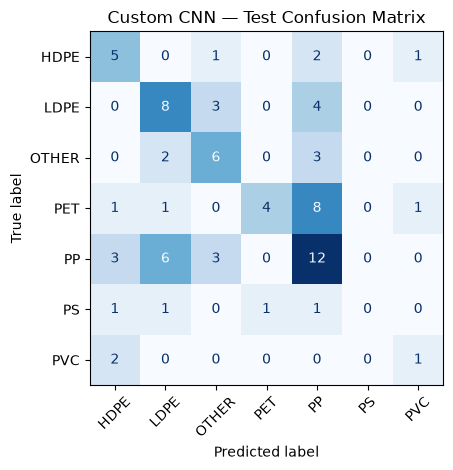


=============== VGG-16 ===============
Test accuracy: 0.6296
Test macro-F1: 0.6125


,precision,recall,f1-score,support
HDPE,1.000,0.667,0.800,9.0
LDPE,0.556,0.667,0.606,15.0
OTHER,0.500,0.455,0.476,11.0
PET,0.600,0.800,0.686,15.0
PP,0.700,0.583,0.636,24.0
PS,0.500,0.250,0.333,4.0
PVC,0.600,1.000,0.750,3.0


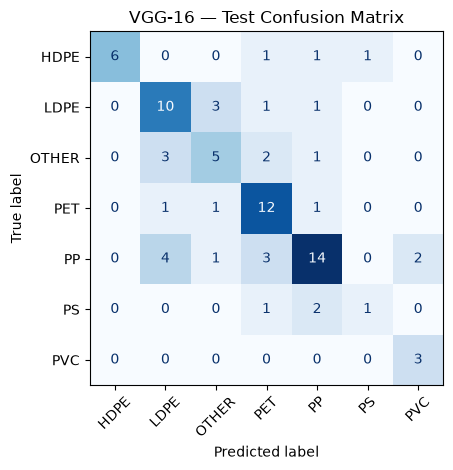


FINAL MODEL COMPARISON


,Model,Test Accuracy,Test Macro-F1
0,Custom CNN,0.4444,0.3770
1,VGG-16,0.6296,0.6125


Comparison saved successfully.


In [12]:
import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)
from torchvision.models import vgg16, VGG16_Weights
from IPython.display import display

# Load the saved best Custom CNN
cnn_checkpoint = torch.load(
    MODEL_DIR / "custom_cnn_best.pt",
    map_location=device,
    weights_only=False
)

cnn = CustomCNN(num_classes=len(classes)).to(device)
cnn.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn.eval()

# Rebuild VGG-16 with the same architecture used during training
vgg = vgg16(weights=None)
vgg.avgpool = torch.nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = torch.nn.Sequential(
    torch.nn.Linear(512, 256),
    torch.nn.ReLU(inplace=True),
    torch.nn.Dropout(0.4),
    torch.nn.Linear(256, len(classes))
)
vgg = vgg.to(device)

vgg_checkpoint = torch.load(
    MODEL_DIR / "vgg16_best.pt",
    map_location=device,
    weights_only=False
)
vgg.load_state_dict(vgg_checkpoint["model_state_dict"])
vgg.eval()

assert cnn_checkpoint["class_to_idx"] == test_ds.class_to_idx
assert vgg_checkpoint["class_to_idx"] == test_ds.class_to_idx

def predict_all(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            predictions = model(images).argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())

    return y_true, y_pred

# Evaluate both models on the exact same test set
y_true, cnn_pred = predict_all(cnn, test_loader)
y_true_vgg, vgg_pred = predict_all(vgg, test_loader)
assert y_true == y_true_vgg

comparison_rows = []

for model_name, predictions in [
    ("Custom CNN", cnn_pred),
    ("VGG-16", vgg_pred),
]:
    acc = accuracy_score(y_true, predictions)
    macro_f1 = f1_score(
        y_true, predictions,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    comparison_rows.append({
        "Model": model_name,
        "Test Accuracy": acc,
        "Test Macro-F1": macro_f1
    })

    print(f"\n{'=' * 15} {model_name} {'=' * 15}")
    print(f"Test accuracy: {acc:.4f}")
    print(f"Test macro-F1: {macro_f1:.4f}")

    report = classification_report(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        output_dict=True,
        zero_division=0
    )

    display(pd.DataFrame(report).T.loc[
        classes, ["precision", "recall", "f1-score", "support"]
    ].round(3))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=list(range(len(classes))),
        display_labels=classes,
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False
    )
    plt.title(f"{model_name} — Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

comparison = pd.DataFrame(comparison_rows)
print("\nFINAL MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "final_test_comparison.csv",
    index=False
)
print("Comparison saved successfully.")


Model Prediction

Models loaded successfully!
Classes: ['HDPE', 'LDPE', 'OTHER', 'PET', 'PP', 'PS', 'PVC']
Device: cpu
Sample test image selected: IMG_6265_jpg.rf.d44e95f76d18de54098e90c98fa96f5f_crop.jpg


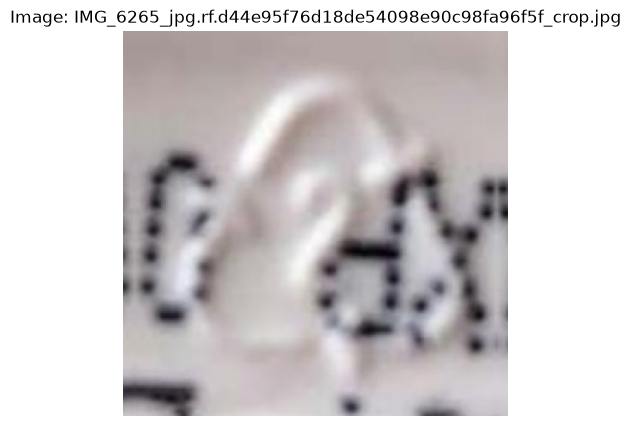


Custom CNN
Predicted plastic: OTHER
Confidence: 21.12%
All class probabilities:
  OTHER: 21.12%
  PP: 21.10%
  LDPE: 17.67%
  PET: 12.04%
  HDPE: 10.56%
  PS: 8.94%
  PVC: 8.56%

VGG-16
Predicted plastic: HDPE
Confidence: 36.31%
All class probabilities:
  HDPE: 36.31%
  PS: 27.51%
  LDPE: 11.21%
  OTHER: 7.40%
  PET: 7.13%
  PP: 6.48%
  PVC: 3.96%


In [13]:
import io
from pathlib import Path

import torch
import torch.nn as nn
from PIL import Image
import matplotlib.pyplot as plt

from torchvision import transforms
from torchvision.models import vgg16

# 1. Device and saved model paths
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_path = Path("PolymerCode-AI/models/custom_cnn_best.pt")
vgg_path = Path("PolymerCode-AI/models/vgg16_best.pt")

if not cnn_path.exists() or not vgg_path.exists():
    raise FileNotFoundError(
        "Model checkpoints are missing. Run the training cells "
        "and save both models before continuing."
    )

# 2. Define Custom CNN architecture
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

    def forward(self, x):
        return self.block(x)


class CustomCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256)
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))


# 3. Load the trained checkpoints
cnn_checkpoint = torch.load(
    cnn_path, map_location=device, weights_only=False
)
vgg_checkpoint = torch.load(
    vgg_path, map_location=device, weights_only=False
)

class_to_idx = cnn_checkpoint["class_to_idx"]
assert class_to_idx == vgg_checkpoint["class_to_idx"], (
    "CNN and VGG-16 use different class mappings."
)

classes = [
    name for name, idx in sorted(
        class_to_idx.items(), key=lambda item: item[1]
    )
]

cnn = CustomCNN(num_classes=len(classes)).to(device)
cnn.load_state_dict(cnn_checkpoint["model_state_dict"])
cnn.eval()

vgg = vgg16(weights=None)
vgg.avgpool = nn.AdaptiveAvgPool2d((1, 1))
vgg.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.4),
    nn.Linear(256, len(classes))
)
vgg = vgg.to(device)
vgg.load_state_dict(vgg_checkpoint["model_state_dict"])
vgg.eval()

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])

print("Models loaded successfully!")
print("Classes:", classes)
print("Device:", device)

# 5. Image for demonstration
uploaded = {}
try:
    from google.colab import files
    uploaded = files.upload()
except Exception:
    uploaded = {}

if not uploaded:
    # Use a sample image from the test set
    test_files = list(Path(DATA_DIR / "test").rglob("*.jpg")) + list(Path(DATA_DIR / "test").rglob("*.png"))
    if test_files:
        sample_path = test_files[0]
        uploaded = {sample_path.name: open(sample_path, "rb").read()}
        print(f"Sample test image selected: {sample_path.name}")

if uploaded:
    image_name = next(iter(uploaded))
    image = Image.open(
        io.BytesIO(uploaded[image_name])
    ).convert("RGB")

    input_tensor = eval_transform(image).unsqueeze(0).to(device)

    # 6. Predict with both models
    results = {}

    for name, model_eval in [
        ("Custom CNN", cnn),
        ("VGG-16", vgg)
    ]:
        with torch.inference_mode():
            logits = model_eval(input_tensor)
            probs = torch.softmax(logits, dim=1)[0]

        idx = probs.argmax().item()

        results[name] = {
            "class": classes[idx],
            "confidence": probs[idx].item() * 100,
            "probabilities": probs.cpu().tolist()
        }

    # 7. Display the image and results
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"Image: {image_name}")
    plt.show()

    for name, result in results.items():
        print(f"\n{'=' * 35}")
        print(name)
        print("Predicted plastic:", result["class"])
        print(f"Confidence: {result['confidence']:.2f}%")
        print("All class probabilities:")

        for i in sorted(
            range(len(classes)),
            key=lambda i: result["probabilities"][i],
            reverse=True
        ):
            print(
                f"  {classes[i]}: "
                f"{result['probabilities'][i] * 100:.2f}%"
            )
